# Chapitre 11 - Cours 1 : transmettre des flux d'événements, les courtiers de messages

Le chapitre 10 traitait des entrées **bornées** : un job lit des fichiers de
taille connue, s'arrête, et son résultat est une donnée dérivée que l'on peut recalculer.
Mais la plupart des données arrivent au fil de l'eau et ne sont jamais « complètes » :
les utilisateurs produisaient des événements hier, en produisent aujourd'hui et en
produiront demain. Découper ce flux en lots quotidiens donne des résultats qui ont un
jour de retard ; le **traitement de flux** (stream processing) pousse l'idée à la limite
en traitant chaque événement dès qu'il arrive.

Ce premier notebook couvre le début de la section *Transmitting Event Streams* :
l'introduction, *Messaging Systems* (*Direct messaging from producers to consumers*,
*Message brokers*, *Message brokers compared to databases*, *Multiple consumers*,
*Acknowledgments and redelivery*). Le cours 2 traitera des courtiers fondés sur un
journal.

**Plan.**

1. Événements, producteurs, consommateurs : pourquoi ne pas simplement interroger une base ?
2. Les deux questions qui distinguent les systèmes de messagerie.
3. La messagerie directe et ses limites.
4. Les courtiers de messages, et ce qui les distingue d'une base de données.
5. Plusieurs consommateurs : répartition de charge et diffusion.
6. Acquittements, relivraison et réordonnancement.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.timelines import SpaceTime
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Événements, producteurs, consommateurs (section *Transmitting Event Streams*)

Dans un contexte de flux, l'enregistrement de base s'appelle un **événement** : un petit
objet autonome et **immuable** qui décrit quelque chose qui s'est produit à un instant
donné (un clic, un achat, une mesure de capteur, une ligne de journal d'un serveur web).
Il porte en général un horodatage lu sur une horloge « heure du jour » (chapitre
8) et il est encodé comme n'importe quelle donnée (JSON, format binaire :
chapitre 4).

Le vocabulaire transpose celui du traitement par lots :

| traitement par lots | traitement de flux |
|---|---|
| un fichier, écrit une fois | un événement, émis une fois par un **producteur** (publisher, sender) |
| lu par plusieurs jobs | traité par plusieurs **consommateurs** (subscribers, recipients) |
| un nom de fichier regroupe des enregistrements | un **sujet** (topic) ou flux regroupe des événements |

**Pourquoi pas une base de données ?** Un producteur pourrait écrire chaque événement dans
une table, et chaque consommateur **interroger périodiquement** (polling) la table pour
trouver les nouveautés. C'est d'ailleurs ce que fait un traitement par lots quotidien.
Mais plus on veut un délai court, plus il faut interroger souvent, et plus la plupart des
interrogations reviennent **vides**. Faisons le calcul : si les événements arrivent selon
un processus de Poisson de taux $\lambda$ et qu'un consommateur interroge toutes les $T$
secondes,

- une interrogation revient vide avec probabilité $e^{-\lambda T}$ ;
- un événement attend en moyenne $T/2$ avant d'être vu ;
- le consommateur envoie $1/T$ requêtes par seconde, quel que soit le trafic.

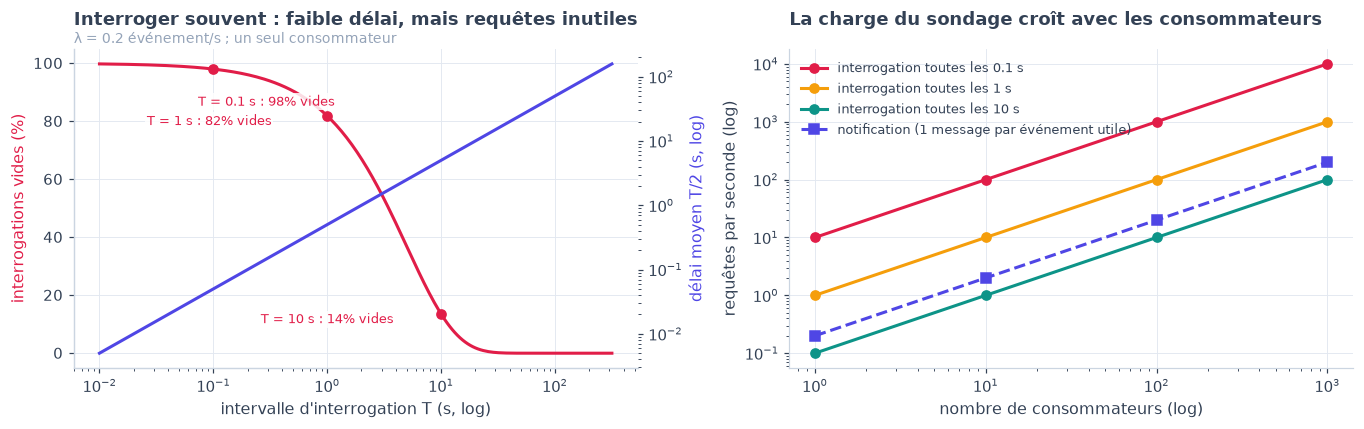

In [2]:
lam = 0.2                                   # 0,2 événement par seconde (12 par minute)
T = np.logspace(-2, 2.5, 200)               # intervalle d'interrogation (s)
vide = np.exp(-lam * T)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12.5, 4))
ax.plot(T, vide * 100, color=ROSE, label="interrogations vides (%)")
ax.set_xscale("log")
ax.set_xlabel("intervalle d'interrogation T (s, log)")
ax.set_ylabel("interrogations vides (%)", color=ROSE)
axb = ax.twinx()
axb.plot(T, T / 2, color=INDIGO, label="délai moyen avant lecture (s)")
axb.set_yscale("log"); axb.set_ylabel("délai moyen T/2 (s, log)", color=INDIGO)
axb.grid(False)
for t0, off in ((0.1, (-10, -24)), (1, (-118, -6)), (10, (-118, -6))):
    ax.plot([t0], [np.exp(-lam * t0) * 100], "o", color=ROSE)
    ax.annotate(f"T = {t0:g} s : {np.exp(-lam * t0):.0%} vides", (t0, np.exp(-lam * t0) * 100),
                off, textcoords="offset points", fontsize=8.5, color=ROSE,
                bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
ax.set_title("Interroger souvent : faible délai, mais requêtes inutiles")
subtitle(ax, f"λ = {lam} événement/s ; un seul consommateur")

n_cons = np.array([1, 10, 100, 1000])
for T0, c in [(0.1, ROSE), (1.0, AMBER), (10.0, TEAL)]:
    ax2.plot(n_cons, n_cons / T0, "o-", color=c, label=f"interrogation toutes les {T0:g} s")
ax2.plot(n_cons, n_cons * lam, "s--", color=INDIGO, label="notification (1 message par événement utile)")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("nombre de consommateurs (log)"); ax2.set_ylabel("requêtes par seconde (log)")
ax2.set_title("La charge du sondage croît avec les consommateurs")
ax2.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()

Avec 12 événements par minute, interroger toutes les 100 ms donne un délai moyen de 50 ms
mais 98 % des requêtes sont inutiles ; mille consommateurs envoient alors 10 000 requêtes
par seconde à la base pour récupérer 200 événements utiles. Mieux vaut que les
consommateurs soient **notifiés** quand un événement apparaît. Les bases de données
relationnelles ont des déclencheurs (triggers), mais ils sont limités et n'ont jamais été
pensés comme un mécanisme de diffusion : des outils spécialisés se sont développés pour
cela.

> **À retenir.** Un flux est une suite non bornée d'événements immuables émis par des
> producteurs et lus par des consommateurs. Interroger une base pour les trouver coûte
> d'autant plus cher que l'on veut un délai court ; on préfère un mécanisme de
> notification.

## 2. Deux questions pour classer les systèmes de messagerie (section *Messaging Systems*)

Un **système de messagerie** reçoit les messages des producteurs et les pousse vers les
consommateurs. Contrairement à un tube Unix ou une connexion TCP (un émetteur, un
récepteur), il accepte plusieurs producteurs et plusieurs consommateurs par sujet : c'est
le modèle **publication/abonnement** (publish/subscribe). Les implémentations sont très
variées ; deux questions aident à les situer.

**1. Que se passe-t-il si les producteurs vont plus vite que les consommateurs ?** Trois
options seulement :

- **perdre** des messages (drop) ;
- les **mettre en tampon** dans une file (buffer), en se demandant ce qui se passe quand
  la file grossit (débordement sur disque ? plantage quand la mémoire est pleine ?) ;
- appliquer une **contre-pression** (backpressure, ou contrôle de flux) : bloquer le
  producteur tant que le tampon est plein, comme le font les tubes Unix et TCP.

Simulons un pic de production : le consommateur traite 100 messages par pas de temps, le
producteur en émet 80 en régime normal et 200 pendant un pic de 30 pas ; le tampon
borné contient 1 000 messages.

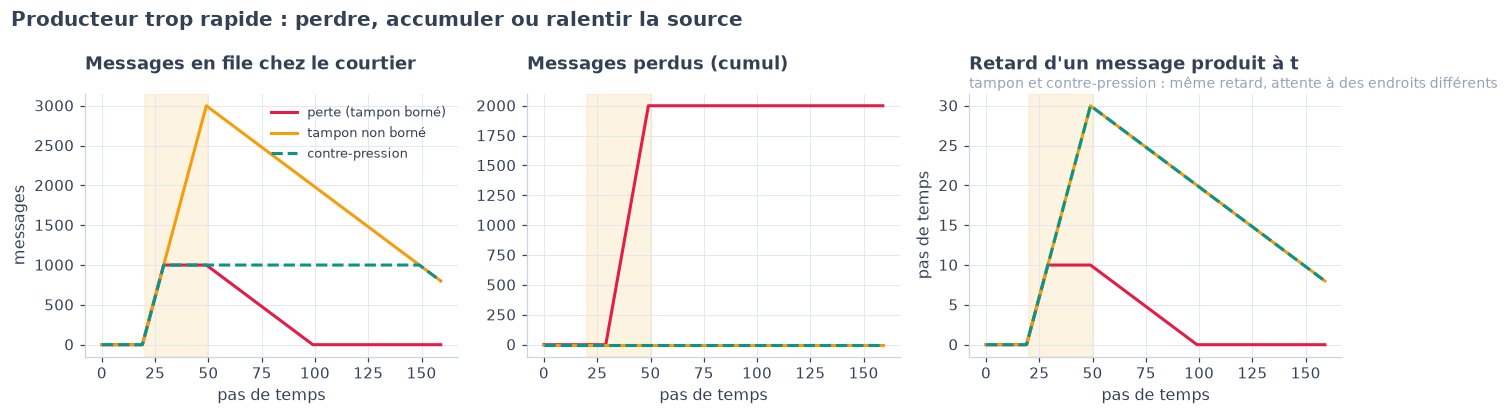

,file max,perdus,retard max (pas),retenus chez le producteur (max)
perte (tampon borné),1000.0,2000.0,10.0,0.0
tampon non borné,3000.0,0.0,30.0,0.0
contre-pression,1000.0,0.0,30.0,2000.0


In [3]:
prod = np.full(160, 80.0)
prod[20:50] = 200.0
res = {pol: st.simulate_overflow(prod, capacity=100, buffer_size=1000, policy=pol)
       for pol in ("drop", "buffer", "backpressure")}
noms = {"drop": "perte (tampon borné)", "buffer": "tampon non borné", "backpressure": "contre-pression"}
cols = {"drop": ROSE, "buffer": AMBER, "backpressure": TEAL}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for pol, r in res.items():
    ls = "--" if pol == "backpressure" else "-"
    axes[0].plot(r["queue"], color=cols[pol], label=noms[pol], ls=ls)
    axes[1].plot(r["lost"], color=cols[pol], label=noms[pol], ls=ls)
    axes[2].plot(r["latency"], color=cols[pol], label=noms[pol], ls=ls)
subtitle(axes[2], "tampon et contre-pression : même retard, attente à des endroits différents")
axes[0].set_title("Messages en file chez le courtier"); axes[0].set_ylabel("messages")
axes[1].set_title("Messages perdus (cumul)")
axes[2].set_title("Retard d'un message produit à t")
axes[2].set_ylabel("pas de temps")
for a in axes:
    a.axvspan(20, 50, color=AMBER, alpha=0.12)
    a.set_xlabel("pas de temps")
axes[0].legend(fontsize=8.5)
finish(fig, "Producteur trop rapide : perdre, accumuler ou ralentir la source")
plt.show()
pd.DataFrame({noms[p]: {"file max": r["queue"].max(), "perdus": r["lost"][-1],
                        "retard max (pas)": r["latency"].max(),
                        "retenus chez le producteur (max)": r["backlog"].max()}
              for p, r in res.items()}).T

Le pic apporte 3 000 messages de trop. La politique de **perte** les sacrifie
(2 000 perdus une fois le tampon de 1 000 plein) mais garde un retard borné ; le
**tampon non borné** n'en perd aucun mais laisse la file grimper à 3 000 messages et le
retard à 30 pas, et la résorption prend du temps car la marge du consommateur n'est que
de 20 messages par pas ; la **contre-pression** ne perd rien non plus et plafonne la
file à 1 000 : le reste attend chez le producteur, qui doit donc pouvoir ralentir (ce qui
est impossible pour un capteur ou un utilisateur qui clique).

**2. Que se passe-t-il si des nœuds tombent en panne ou se déconnectent ?** Comme pour une
base, la durabilité demande d'écrire sur disque et/ou de répliquer, ce qui a un coût. Si
l'on peut perdre quelques messages, on obtient plus de débit et moins de latence sur le
même matériel. Tout dépend de l'application : perdre de temps en temps une mesure
périodique de capteur est sans gravité (une nouvelle valeur arrive bientôt), mais si l'on
**compte** des événements, chaque message perdu fausse le compteur.

> **À retenir.** Face à un producteur trop rapide, un système de messagerie perd, met en
> tampon ou ralentit le producteur ; face aux pannes, il choisit entre durabilité et
> performance. Ces deux réponses suffisent presque à le caractériser.

## 3. La messagerie directe (section *Direct messaging from producers to consumers*)

Certains systèmes relient directement producteurs et consommateurs, sans intermédiaire :

- la **multidiffusion UDP**, très utilisée pour les flux de cotations boursières où la
  latence prime (le protocole applicatif retransmet les paquets perdus, le producteur
  doit donc garder ce qu'il a envoyé) ;
- des bibliothèques de messagerie sans courtier comme ZeroMQ et nanomsg ;
- des agents de collecte de métriques comme StatsD, qui envoient leurs mesures en UDP non
  fiable ;
- les appels HTTP ou RPC directs vers un consommateur qui expose un service, par exemple
  les **webhooks** (on enregistre l'URL de rappel d'un service auprès d'un autre, qui
  l'appelle à chaque événement).

Ces approches fonctionnent bien dans leur niche, mais supposent en général que
producteurs et consommateurs restent en ligne : un consommateur déconnecté rate les
messages envoyés pendant son absence, et si le producteur tombe en panne, il perd le
tampon des messages qu'il devait retransmettre. L'exemple de StatsD illustre la
différence entre **compteurs** et **jauges** face aux pertes.

In [4]:
rng = np.random.default_rng(1)
n_ev = 1_000_000
pertes = [0.0, 0.001, 0.01, 0.05]
rows = []
for p in pertes:
    recus = rng.random(n_ev) >= p
    # compteur : on additionne des incréments « +1 » ; jauge : on envoie la valeur courante
    # (ici la file d'attente d'un serveur) toutes les 10 s, et on garde la dernière reçue
    jauge = np.cumsum(rng.normal(0, 1, 8640)) + 50          # une journée, un envoi toutes les 10 s
    recue = rng.random(8640) >= p
    recue[0] = True
    derniere = jauge[np.maximum.accumulate(np.where(recue, np.arange(8640), 0))]
    rows.append({"perte UDP": f"{p:.1%}", "compteur reçu": int(recus.sum()),
                 "erreur du compteur": f"{(recus.sum() - n_ev) / n_ev:+.2%}",
                 "jauge : erreur moyenne": f"{np.abs(derniere - jauge).mean():.3f}",
                 "jauge : envois en retard (%)": f"{(derniere != jauge).mean():.1%}"})
pd.DataFrame(rows).set_index("perte UDP")

,compteur reçu,erreur du compteur,jauge : erreur moyenne,jauge : envois en retard (%)
perte UDP,,,,
0.0%,1000000,+0.00%,0.000,0.0%
0.1%,998963,-0.10%,0.001,0.1%
1.0%,989961,-1.00%,0.007,0.9%
5.0%,950193,-4.98%,0.040,4.9%


Un compteur transmis par incréments perd exactement la proportion de paquets perdus, en
silence : avec 1 % de pertes, le million d'événements devient 990 000 environ, et rien
n'indique que le chiffre est faux, et l'erreur s'accumule sans fin. Une jauge (une valeur
courante envoyée toutes les 10 s, comme une longueur de file), elle, est rafraîchie par
la valeur suivante : une perte ne la rend fausse que pendant un intervalle, et son
erreur moyenne reste minuscule. C'est pourquoi les métriques de
StatsD ne sont, au mieux, qu'approchées.

> **À retenir.** La messagerie directe a une latence minimale mais une tolérance aux
> pannes limitée : l'application doit accepter des pertes, et un consommateur absent rate
> ce qui a été émis pendant son absence.

## 4. Les courtiers de messages (sections *Message brokers* et *Message brokers compared to databases*)

L'alternative la plus répandue est de passer par un **courtier de messages** (message
broker, ou file de messages, message queue) : un serveur, au fond une sorte de base de
données optimisée pour les flux de messages, auquel producteurs et consommateurs se
connectent comme clients. En centralisant les données, le courtier tolère des clients qui
vont et viennent, et la question de la durabilité lui revient (certains gardent les
messages en mémoire, d'autres les écrivent sur disque). Face à des consommateurs lents,
il met en général les messages en file sans limite. Conséquence : la consommation est
**asynchrone**, le producteur attend seulement que le courtier ait accepté le message, pas
qu'il ait été traité.

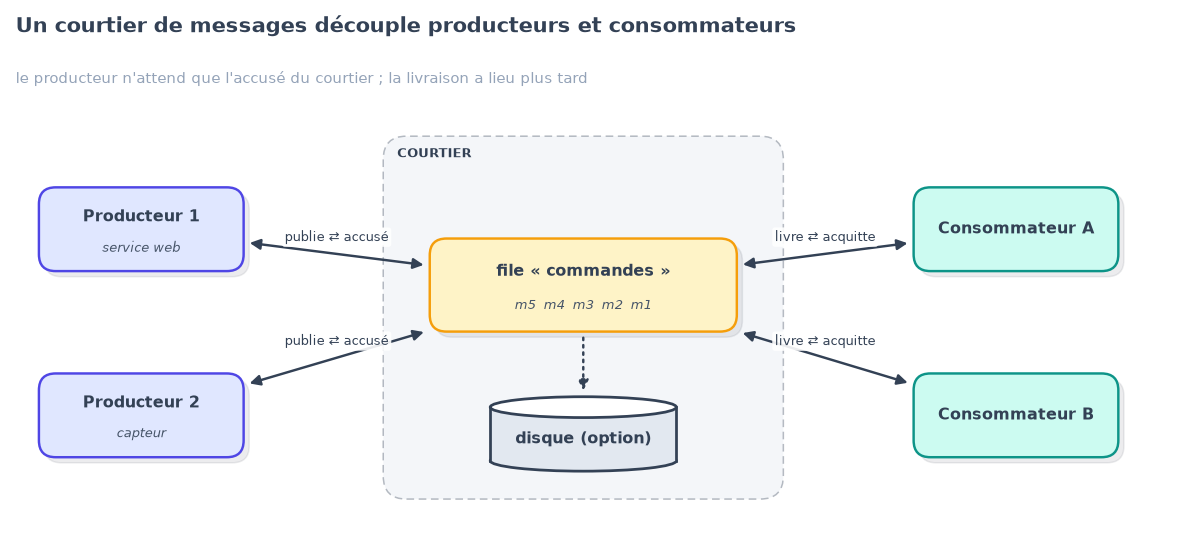

In [5]:
d = Diagram(12.5, 4.6, title="Un courtier de messages découple producteurs et consommateurs",
            subtitle="le producteur n'attend que l'accusé du courtier ; la livraison a lieu plus tard")
d.box("p1", 1.4, 3.2, "Producteur 1", sub="service web", color=INDIGO)
d.box("p2", 1.4, 1.2, "Producteur 2", sub="capteur", color=INDIGO)
d.group(4.0, 0.3, 8.3, 4.2, "courtier", color=SLATE)
d.box("q", 6.15, 2.6, "file « commandes »", sub="m5  m4  m3  m2  m1", color=AMBER, w=3.3, h=1.0)
d.box("disk", 6.15, 1.0, "disque (option)", color=SLATE, kind="db", w=2.0, h=0.8)
d.box("c1", 10.8, 3.2, "Consommateur A", color=TEAL)
d.box("c2", 10.8, 1.2, "Consommateur B", color=TEAL)
d.arrow("p1", "q", "publie ⇄ accusé", both=True)
d.arrow("p2", "q", "publie ⇄ accusé", both=True)
d.arrow("q", "disk", "", style="dotted")
d.arrow("q", "c1", "livre ⇄ acquitte", both=True)
d.arrow("q", "c2", "livre ⇄ acquitte", both=True)
d.show()

Certains courtiers participent même à des validations à deux phases (XA, JTA :
chapitre 9), ce qui les rapproche
encore des bases de données. Il reste des différences pratiques importantes :

In [6]:
pd.DataFrame({
    "base de données": ["jusqu'à suppression explicite", "grand, sur disque",
                        "index secondaires, langage de requête riche",
                        "instantané à un instant : le client ne sait pas que son résultat a vieilli"],
    "courtier de messages (style AMQP/JMS)": ["supprimé une fois livré et acquitté", "petit : les files sont supposées courtes",
                                              "abonnement à des sujets selon un motif",
                                              "pas de requête arbitraire, mais notification de chaque nouveau message"],
}, index=["durée de vie des données", "ensemble de travail", "sélection des données", "changements"])

,base de données,courtier de messages (style AMQP/JMS)
durée de vie des données,jusqu'à suppression explicite,supprimé une fois livré et acquitté
ensemble de travail,"grand, sur disque",petit : les files sont supposées courtes
sélection des données,"index secondaires, langage de requête riche",abonnement à des sujets selon un motif
changements,instantané à un instant : le client ne sait pa...,"pas de requête arbitraire, mais notification d..."


Le point « ensemble de travail » a une conséquence mesurable : si les consommateurs sont
lents et que la file déborde sur disque, chaque message coûte plus cher à traiter et le
débit global se dégrade, ce qui ralentit encore la vidange de la file. Cette vision
« traditionnelle » est celle des standards JMS et AMQP, implémentés par RabbitMQ,
ActiveMQ, HornetQ, Qpid, TIBCO Enterprise Message Service, IBM MQ, Azure Service Bus ou
Google Cloud Pub/Sub. On peut se servir d'une base comme d'une file, mais l'optimiser pour
cet usage n'a rien d'évident.

> **À retenir.** Un courtier est une base spécialisée : il garde peu de données et peu de
> temps, n'offre pas de requêtes, mais notifie les consommateurs. Il absorbe les
> déconnexions des clients et rend la consommation asynchrone.